# Vision Transformer (ViT) Image Interpretation
## Clinical Objects Edition

This notebook demonstrates how to interpret **Vision Transformers (ViT)** on photographs of everyday clinical equipment. We'll explore the attention-based interpretation techniques that are unique to transformers.

It is the companion to `s3_01_cnn_image_interpretation.ipynb` and uses **the same five images in the same order**, so the two architectures can be compared directly on identical inputs.

### Why a general-purpose model rather than a diagnostic one?

As in the CNN notebook, the model is **ImageNet-pretrained** (ViT-B/16 with SWAG weights) and the subjects are ordinary clinical objects — stethoscope, syringe, pill bottle, ambulance, crutches — all of which are real ImageNet-1k classes. The subject of the lesson is the interpretability method, not the diagnosis: attention maps and attention rollout behave identically whichever domain the transformer was trained on. Section 12 covers what changes for real medical imaging.

### CNN vs Transformer: Key Differences

| Aspect | CNN | Vision Transformer |
|--------|-----|--------------------|
| Processing | Sliding filters (local) | Self-attention (global) |
| Input | Pixels directly | Image patches as tokens |
| Receptive Field | Grows with depth | Global from layer 1 |
| Interpretation | Grad-CAM, Saliency | Attention maps, Grad-CAM |

### How Vision Transformers Work
1. **Patch Embedding**: Image is split into fixed-size patches (e.g., 16x16)
2. **Position Encoding**: Patches get positional information
3. **Transformer Blocks**: Self-attention allows patches to "communicate"
4. **Classification**: [CLS] token aggregates information for prediction

## Learning Objectives
- Understand how ViT processes images differently than CNNs
- Visualize attention patterns across transformer layers
- See which image patches the model attends to
- Compare attention-based interpretation with Grad-CAM


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models, transforms
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import urllib.request
import json
import io
from IPython.display import display, HTML

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check for GPU/MPS availability
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: mps


## 1. Loading a Pre-trained Vision Transformer

We'll use ViT-B/16 with **SWAG weights** (Supervised Weakly from hashtAGs). SWAG models are pre-trained on 3.6 billion Instagram images, giving them much better feature representations than standard ImageNet training.

Key specs:
- **Input size**: 384x384 pixels (larger than standard 224x224)
- **Patches**: 24x24 = 576 patches (each 16x16 pixels)
- **Accuracy**: 85.3% top-1 on ImageNet (vs 81.1% for standard weights)
- **Layers**: 12 transformer blocks with 12 attention heads each

In [2]:
# Load pre-trained Vision Transformer
# Using SWAG weights which have much higher accuracy (85.3% vs 81.1% for V1)
weights = models.ViT_B_16_Weights.IMAGENET1K_SWAG_E2E_V1
model = models.vit_b_16(weights=weights)
model = model.to(device)
model.eval()

print(f"Model: Vision Transformer (ViT-B/16) with SWAG weights")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"\nArchitecture:")
print(f"  - Patch size: 16x16 pixels")
print(f"  - Input size: 384x384 (SWAG uses larger images)")
print(f"  - Number of patches: 24x24 = 576")
print(f"  - Hidden dimension: 768")
print(f"  - Transformer layers: 12")
print(f"  - Attention heads per layer: 12")
print(f"\nNote: SWAG (Supervised Weakly from hashtAGs) training")
print(f"      uses 3.6B Instagram images for better features!\")")

Model: Vision Transformer (ViT-B/16) with SWAG weights
Total parameters: 86,859,496

Architecture:
  - Patch size: 16x16 pixels
  - Input size: 384x384 (SWAG uses larger images)
  - Number of patches: 24x24 = 576
  - Hidden dimension: 768
  - Transformer layers: 12
  - Attention heads per layer: 12

Note: SWAG (Supervised Weakly from hashtAGs) training
      uses 3.6B Instagram images for better features!")


In [3]:
# Load ImageNet class labels
IMAGENET_LABELS_URL = "https://raw.githubusercontent.com/anishathalye/imagenet-simple-labels/master/imagenet-simple-labels.json"

try:
    with urllib.request.urlopen(IMAGENET_LABELS_URL) as url:
        imagenet_labels = json.loads(url.read().decode())
    print(f"Loaded {len(imagenet_labels)} ImageNet class labels")
except Exception as e:
    print(f"Could not load labels: {e}")
    imagenet_labels = [f"class_{i}" for i in range(1000)]

Loaded 1000 ImageNet class labels


## 2. Image Preprocessing

ViT uses the same preprocessing as CNNs for ImageNet, but conceptually the image will be split into patches.

In [4]:
# Preprocessing for SWAG model (uses 384x384 images)
INPUT_SIZE = 384  # SWAG uses larger images than standard ViT

preprocess = transforms.Compose([
    transforms.Resize(INPUT_SIZE, interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.CenterCrop(INPUT_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def load_image(image_path_or_url):
    """Load an image from a file path or URL."""
    if image_path_or_url.startswith('http'):
        req = urllib.request.Request(
            image_path_or_url,
            headers={'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36'}
        )
        with urllib.request.urlopen(req) as response:
            img_data = response.read()
        img = Image.open(io.BytesIO(img_data)).convert('RGB')
    else:
        img = Image.open(image_path_or_url).convert('RGB')
    return img

def preprocess_image(img):
    """Preprocess image for the model."""
    img_tensor = preprocess(img)
    img_tensor = img_tensor.unsqueeze(0)
    return img_tensor.to(device)

print(f"Preprocessing functions ready (input size: {INPUT_SIZE}x{INPUT_SIZE})")

Preprocessing functions ready (input size: 384x384)


## 3. Sample Clinical Object Images

We use exactly the same five images as the CNN notebook, in the same order, so the comparison in Section 12 is like-for-like. Each key is a real ImageNet-1k class:

| Key | ImageNet class (index) | Why it makes a good demonstration |
|-----|------------------------|-----------------------------------|
| `stethoscope` | `stethoscope` (823) | Thin, high-contrast tubing — a sharp test of how precisely a method localizes |
| `syringe` | `syringe` (845) | Small object, plain background — the easy case, useful as a baseline |
| `pill_bottle` | `pill bottle` (720) | The cap and label carry the class, not the overall silhouette |
| `ambulance` | `ambulance` (407) | Large object where the markings matter more than the shape |
| `crutches` | `crutch` (523) | Object *and* a person in frame — does the model look at the right one? |


Loading: stethoscope


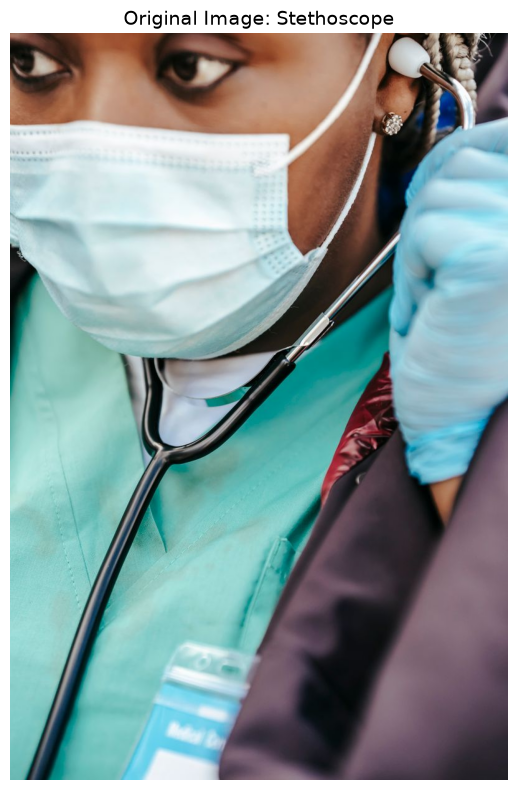

In [5]:
# Sample clinical object images (free Pexels stock photography).
# Identical to s3_01_cnn_image_interpretation.ipynb so the two architectures
# can be compared on the same inputs.
sample_images = {
    'stethoscope': 'https://images.pexels.com/photos/6098063/pexels-photo-6098063.jpeg?w=800',
    'syringe':     'https://images.pexels.com/photos/6631411/pexels-photo-6631411.jpeg?w=800',
    'pill_bottle': 'https://images.pexels.com/photos/11931275/pexels-photo-11931275.jpeg?w=800',
    'ambulance':   'https://images.pexels.com/photos/8942097/pexels-photo-8942097.jpeg?w=800',
    'crutches':    'https://images.pexels.com/photos/4497823/pexels-photo-4497823.jpeg?w=800',
}

# Load a sample image
selected_image = 'stethoscope'  # Try: 'syringe', 'pill_bottle', 'ambulance', 'crutches'

print(f"Loading: {selected_image}")
original_img = load_image(sample_images[selected_image])
img_tensor = preprocess_image(original_img)

# Display the original image
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(original_img)
ax.axis('off')
ax.set_title(f'Original Image: {selected_image.replace("_", " ").title()}', fontsize=14)
plt.tight_layout()
plt.show()


## 4. Visualizing Patch Embedding

Let's see how ViT splits the image into patches. This is fundamentally different from how CNNs process images!

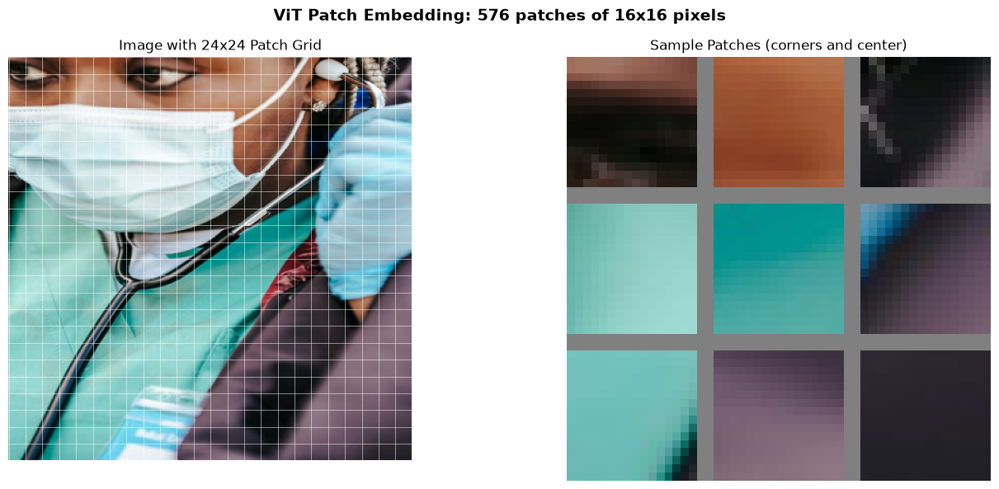


ViT processes this image as 576 tokens (patches) + 1 [CLS] token = 577 tokens


In [6]:
def visualize_patches(img, patch_size=16, input_size=384):
    """Visualize how ViT splits an image into patches."""
    # Resize image to input size
    img_resized = img.resize((input_size, input_size))
    img_array = np.array(img_resized)
    
    num_patches = input_size // patch_size  # 24 patches per side for 384x384
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Original image with grid overlay
    axes[0].imshow(img_array)
    axes[0].set_title(f'Image with {num_patches}x{num_patches} Patch Grid', fontsize=12)
    
    # Draw grid lines
    for i in range(num_patches + 1):
        axes[0].axhline(y=i * patch_size, color='white', linewidth=0.5, alpha=0.7)
        axes[0].axvline(x=i * patch_size, color='white', linewidth=0.5, alpha=0.7)
    axes[0].axis('off')
    
    # Show some individual patches - adjust positions for larger grid
    mid = num_patches // 2
    last = num_patches - 1
    patch_positions = [(0, 0), (0, mid), (0, last), 
                       (mid, 0), (mid, mid), (mid, last),
                       (last, 0), (last, mid), (last, last)]
    
    patch_grid = np.zeros((3 * patch_size + 4, 3 * patch_size + 4, 3), dtype=np.uint8)
    patch_grid.fill(128)  # Gray background
    
    for idx, (row, col) in enumerate(patch_positions):
        patch = img_array[row*patch_size:(row+1)*patch_size, 
                         col*patch_size:(col+1)*patch_size]
        grid_row = idx // 3
        grid_col = idx % 3
        y_start = grid_row * (patch_size + 2)
        x_start = grid_col * (patch_size + 2)
        patch_grid[y_start:y_start+patch_size, x_start:x_start+patch_size] = patch
    
    axes[1].imshow(patch_grid)
    axes[1].set_title('Sample Patches (corners and center)', fontsize=12)
    axes[1].axis('off')
    
    plt.suptitle(f'ViT Patch Embedding: {num_patches*num_patches} patches of {patch_size}x{patch_size} pixels', 
                 fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print(f"\nViT processes this image as {num_patches*num_patches} tokens (patches) + 1 [CLS] token = {num_patches*num_patches + 1} tokens")

visualize_patches(original_img, input_size=INPUT_SIZE)

## 5. Basic Classification

Let's see what the ViT predicts for our image.


Top 5 Predictions (Vision Transformer):
---------------------------------------------
1. stethoscope                    96.67%
2. lab coat                        0.54%
3. syringe                         0.53%
4. stretcher                       0.34%
5. Band-Aid                        0.27%


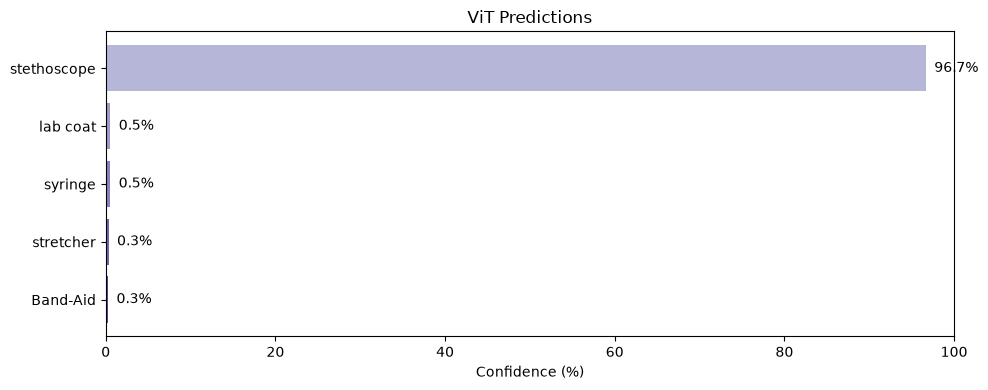

In [7]:
def get_predictions(model, img_tensor, top_k=5):
    """Get top-k predictions from the model."""
    with torch.no_grad():
        outputs = model(img_tensor)
        probabilities = F.softmax(outputs, dim=1)
        top_probs, top_indices = torch.topk(probabilities, top_k)
    
    predictions = []
    for prob, idx in zip(top_probs[0], top_indices[0]):
        predictions.append({
            'class': imagenet_labels[idx.item()],
            'probability': prob.item(),
            'index': idx.item()
        })
    return predictions

# Get predictions
predictions = get_predictions(model, img_tensor)

# Display predictions
print("Top 5 Predictions (Vision Transformer):")
print("-" * 45)
for i, pred in enumerate(predictions):
    print(f"{i+1}. {pred['class']:30s} {pred['probability']*100:5.2f}%")

# Visualize predictions
fig, ax = plt.subplots(figsize=(10, 4))
classes = [p['class'] for p in predictions]
probs = [p['probability'] * 100 for p in predictions]
colors = plt.cm.Purples(np.linspace(0.4, 0.8, len(predictions)))
bars = ax.barh(classes[::-1], probs[::-1], color=colors[::-1])
ax.set_xlabel('Confidence (%)')
ax.set_title('ViT Predictions')
ax.set_xlim(0, 100)
for bar, prob in zip(bars, probs[::-1]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, 
            f'{prob:.1f}%', va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 6. Extracting Attention Weights

The key interpretability tool for transformers is **attention visualization**. Each attention head learns to focus on different relationships between patches.

We'll hook into the transformer layers to extract attention weights.

In [8]:
class AttentionExtractor:
    """Extract attention weights from ViT."""
    def __init__(self, model):
        self.model = model
        self.attentions = []
        self.hooks = []
        
        # Register hooks on all encoder blocks
        for i, block in enumerate(model.encoder.layers):
            hook = block.self_attention.register_forward_hook(self._get_attention_hook(i))
            self.hooks.append(hook)
    
    def _get_attention_hook(self, layer_idx):
        def hook(module, input, output):
            # ViT's MultiheadAttention returns (attn_output, attn_weights)
            # We need to compute attention weights manually
            pass
        return hook
    
    def get_attention_weights(self, x):
        """Forward pass and extract attention from all layers."""
        self.attentions = []
        
        # Get patch embeddings
        x = self.model._process_input(x)
        n = x.shape[0]
        
        # Expand class token
        batch_class_token = self.model.class_token.expand(n, -1, -1)
        x = torch.cat([batch_class_token, x], dim=1)
        
        # Process through encoder layers and capture attention
        for layer in self.model.encoder.layers:
            # Get Q, K, V
            qkv = layer.self_attention.in_proj_weight
            qkv_bias = layer.self_attention.in_proj_bias
            
            # Layer norm before attention
            x_norm = layer.ln_1(x)
            
            # Compute attention manually to get weights
            num_heads = layer.self_attention.num_heads
            head_dim = layer.self_attention.head_dim
            
            # Project to Q, K, V
            qkv_out = F.linear(x_norm, qkv, qkv_bias)
            qkv_out = qkv_out.reshape(n, -1, 3, num_heads, head_dim).permute(2, 0, 3, 1, 4)
            q, k, v = qkv_out[0], qkv_out[1], qkv_out[2]
            
            # Compute attention weights
            scale = head_dim ** -0.5
            attn = (q @ k.transpose(-2, -1)) * scale
            attn = attn.softmax(dim=-1)
            
            self.attentions.append(attn.detach().cpu())
            
            # Complete the forward pass for this layer
            attn_out = (attn.to(x.device) @ v).transpose(1, 2).reshape(n, -1, num_heads * head_dim)
            attn_out = layer.self_attention.out_proj(attn_out)
            x = x + attn_out
            x = x + layer.mlp(layer.ln_2(x))
        
        return self.attentions
    
    def remove_hooks(self):
        for hook in self.hooks:
            hook.remove()

# Create attention extractor
attn_extractor = AttentionExtractor(model)

# Extract attention weights
with torch.no_grad():
    attentions = attn_extractor.get_attention_weights(img_tensor)

print(f"Extracted attention from {len(attentions)} layers")
print(f"Attention shape per layer: {attentions[0].shape}")
print(f"  - Batch size: {attentions[0].shape[0]}")
print(f"  - Attention heads: {attentions[0].shape[1]}")
print(f"  - Tokens (patches + CLS): {attentions[0].shape[2]}")

Extracted attention from 12 layers
Attention shape per layer: torch.Size([1, 12, 577, 577])
  - Batch size: 1
  - Attention heads: 12
  - Tokens (patches + CLS): 577


## 7. Visualizing Attention Patterns

Let's visualize what each attention head focuses on. We'll look at the attention from the [CLS] token to all image patches - this shows which patches contribute most to the classification decision.

Final layer attention (closest to classification decision):


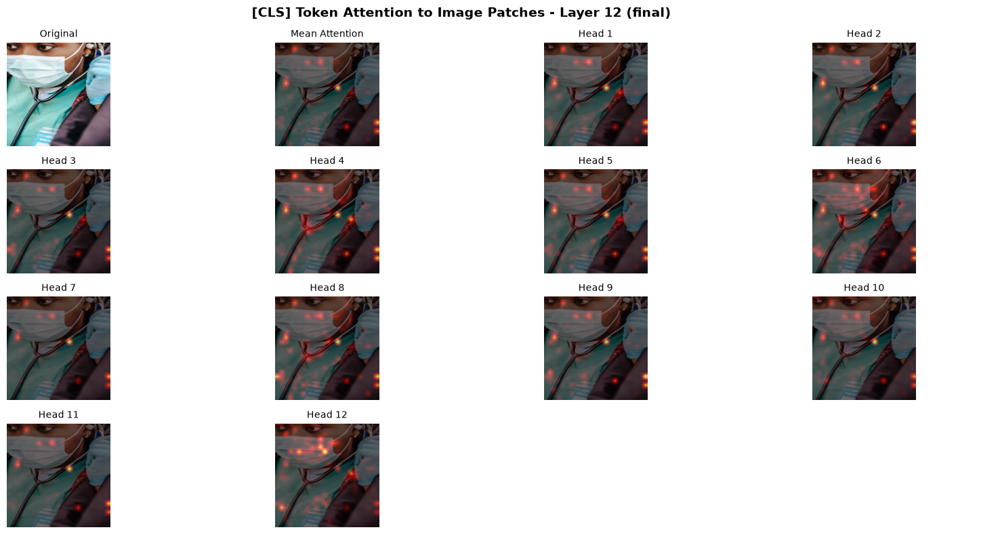

In [9]:
def visualize_cls_attention(img, attentions, layer_idx=-1, figsize=(16, 8)):
    """Visualize attention from [CLS] token to image patches."""
    # Get attention from specified layer
    attn = attentions[layer_idx][0]  # Remove batch dimension
    num_heads = attn.shape[0]
    
    # Get attention from CLS token (index 0) to all patches (indices 1:)
    cls_attn = attn[:, 0, 1:]  # Shape: (num_heads, num_patches)
    
    # Reshape to spatial grid
    grid_size = int(np.sqrt(cls_attn.shape[1]))
    cls_attn = cls_attn.reshape(num_heads, grid_size, grid_size)
    
    # Resize original image to input size
    img_resized = img.resize((INPUT_SIZE, INPUT_SIZE))
    
    # Plot attention heads
    cols = 4
    rows = (num_heads + cols) // cols  # +1 for original image
    
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = axes.flatten()
    
    # Show original image
    axes[0].imshow(img_resized)
    axes[0].set_title('Original', fontsize=10)
    axes[0].axis('off')
    
    # Show mean attention
    mean_attn = cls_attn.mean(dim=0).numpy()
    mean_attn_resized = np.array(Image.fromarray((mean_attn * 255).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
    axes[1].imshow(img_resized)
    axes[1].imshow(mean_attn_resized, cmap='hot', alpha=0.6)
    axes[1].set_title('Mean Attention', fontsize=10)
    axes[1].axis('off')
    
    # Show individual heads
    for i in range(min(num_heads, len(axes) - 2)):
        head_attn = cls_attn[i].numpy()
        head_attn_resized = np.array(Image.fromarray((head_attn * 255 / head_attn.max()).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
        
        axes[i + 2].imshow(img_resized)
        axes[i + 2].imshow(head_attn_resized, cmap='hot', alpha=0.6)
        axes[i + 2].set_title(f'Head {i+1}', fontsize=10)
        axes[i + 2].axis('off')
    
    # Hide unused subplots
    for i in range(num_heads + 2, len(axes)):
        axes[i].axis('off')
    
    layer_name = f"Layer {layer_idx + 1}" if layer_idx >= 0 else f"Layer {len(attentions) + layer_idx + 1} (final)"
    plt.suptitle(f'[CLS] Token Attention to Image Patches - {layer_name}', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Visualize attention from the final layer
print("Final layer attention (closest to classification decision):")
visualize_cls_attention(original_img, attentions, layer_idx=-1)

How attention evolves through the network:
Early layers: more diffuse attention
Later layers: more focused on relevant features



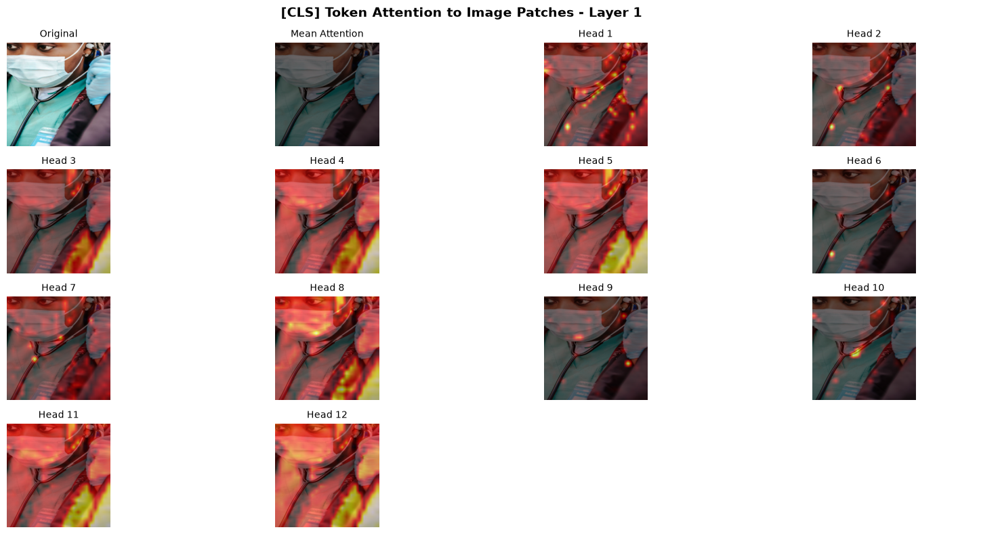

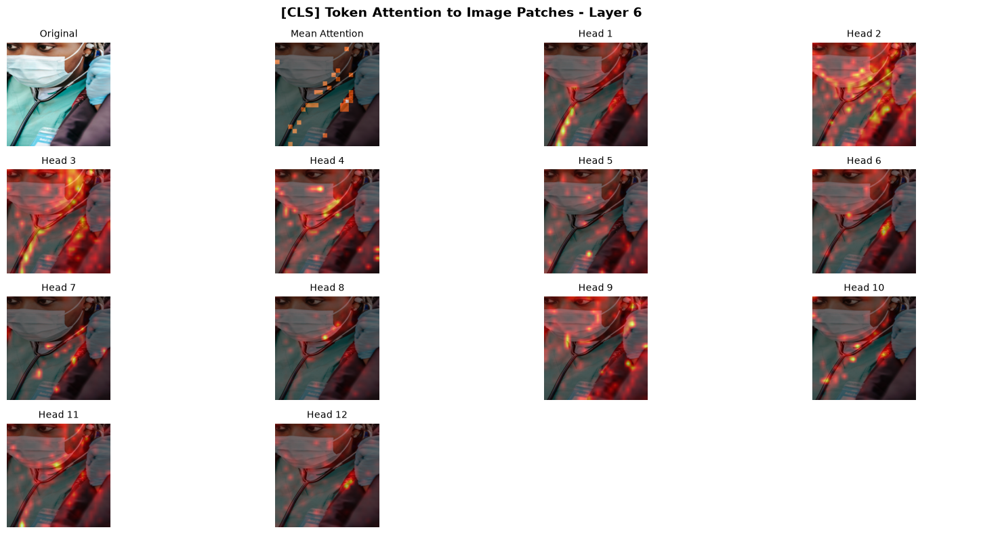

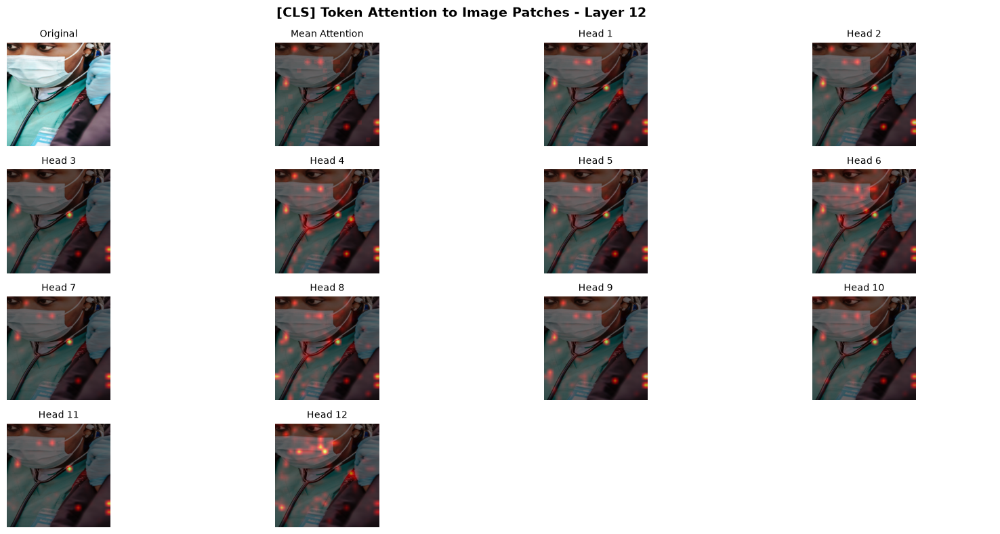

In [10]:
# Compare attention across layers
print("How attention evolves through the network:")
print("Early layers: more diffuse attention")
print("Later layers: more focused on relevant features\n")

visualize_cls_attention(original_img, attentions, layer_idx=0)
visualize_cls_attention(original_img, attentions, layer_idx=5)
visualize_cls_attention(original_img, attentions, layer_idx=11)

## 8. Attention Rollout

**Attention Rollout** aggregates attention across all layers to show the complete flow of information from input patches to the final classification. This gives a more holistic view than single-layer attention.

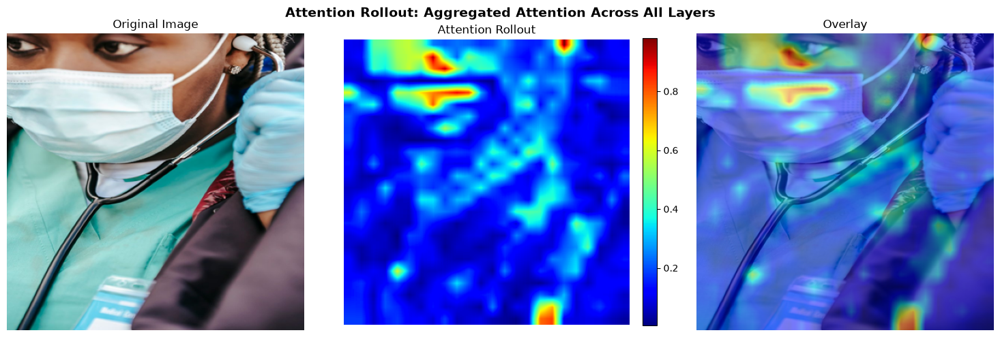


Attention rollout shows the cumulative information flow from patches to classification.


In [11]:
def attention_rollout(attentions, discard_ratio=0.0, head_fusion='mean'):
    """
    Compute attention rollout across all layers.
    
    Args:
        attentions: List of attention tensors from each layer
        discard_ratio: Fraction of lowest attention values to discard
        head_fusion: How to combine attention heads ('mean', 'max', 'min')
    """
    result = torch.eye(attentions[0].shape[-1])
    
    for attention in attentions:
        # Fuse attention heads
        if head_fusion == 'mean':
            attention_heads_fused = attention.mean(dim=1)[0]  # Average over heads
        elif head_fusion == 'max':
            attention_heads_fused = attention.max(dim=1)[0][0]
        elif head_fusion == 'min':
            attention_heads_fused = attention.min(dim=1)[0][0]
        else:
            raise ValueError(f"Unknown head fusion: {head_fusion}")
        
        # Discard lowest attention values
        if discard_ratio > 0:
            flat = attention_heads_fused.view(-1)
            threshold = flat.kthvalue(int(flat.numel() * discard_ratio))[0]
            attention_heads_fused = attention_heads_fused.clone()
            attention_heads_fused[attention_heads_fused < threshold] = 0
        
        # Add residual connection (identity)
        I = torch.eye(attention_heads_fused.shape[-1])
        attention_heads_fused = (attention_heads_fused + I) / 2
        
        # Normalize rows
        attention_heads_fused = attention_heads_fused / attention_heads_fused.sum(dim=-1, keepdim=True)
        
        # Multiply with previous result
        result = attention_heads_fused @ result
    
    return result

def visualize_attention_rollout(img, attentions, figsize=(15, 5)):
    """Visualize attention rollout."""
    # Compute rollout
    rollout = attention_rollout(attentions)
    
    # Get attention from CLS token to patches
    cls_attention = rollout[0, 1:].numpy()  # Exclude CLS-to-CLS
    
    # Reshape to spatial grid
    grid_size = int(np.sqrt(len(cls_attention)))
    cls_attention = cls_attention.reshape(grid_size, grid_size)
    
    # Resize for overlay
    img_resized = img.resize((INPUT_SIZE, INPUT_SIZE))
    img_array = np.array(img_resized) / 255.0
    
    # Normalize and resize attention
    cls_attention = (cls_attention - cls_attention.min()) / (cls_attention.max() - cls_attention.min())
    cls_attention_resized = np.array(Image.fromarray((cls_attention * 255).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
    
    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=figsize)
    
    # Original
    axes[0].imshow(img_resized)
    axes[0].set_title('Original Image', fontsize=12)
    axes[0].axis('off')
    
    # Attention rollout heatmap
    im = axes[1].imshow(cls_attention_resized, cmap='jet')
    axes[1].set_title('Attention Rollout', fontsize=12)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    # Overlay
    heatmap_colored = plt.cm.jet(cls_attention_resized)[:, :, :3]
    overlay = 0.5 * heatmap_colored + 0.5 * img_array
    axes[2].imshow(np.clip(overlay, 0, 1))
    axes[2].set_title('Overlay', fontsize=12)
    axes[2].axis('off')
    
    plt.suptitle('Attention Rollout: Aggregated Attention Across All Layers', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return cls_attention_resized

rollout_attention = visualize_attention_rollout(original_img, attentions)
print("\nAttention rollout shows the cumulative information flow from patches to classification.")

## 9. Grad-CAM for Vision Transformers

We can also apply Grad-CAM to ViT! We'll use gradients with respect to the patch embeddings after the transformer layers.

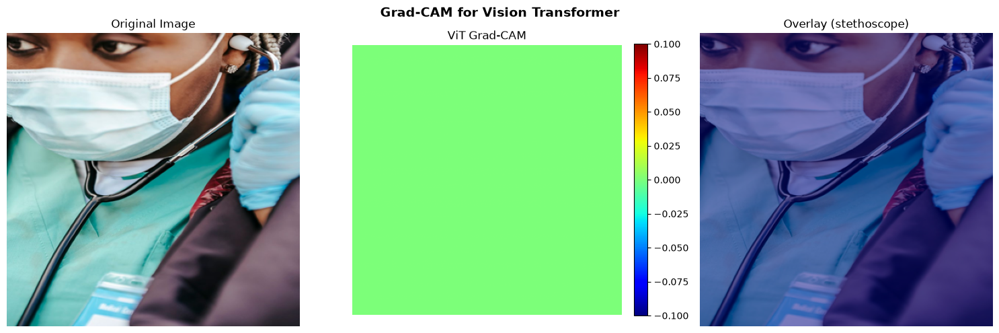

In [12]:
class ViTGradCAM:
    """Grad-CAM implementation for Vision Transformer."""
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None
        
        # Hook the final layer norm before the classification head
        self.model.encoder.ln.register_forward_hook(self._save_activation)
        self.model.encoder.ln.register_full_backward_hook(self._save_gradient)
    
    def _save_activation(self, module, input, output):
        self.activations = output.detach()
    
    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()
    
    def __call__(self, x, target_class=None):
        """Generate Grad-CAM heatmap for ViT."""
        self.model.zero_grad()
        output = self.model(x)
        
        if target_class is None:
            target_class = output.argmax(dim=1).item()
        
        # Backward pass
        one_hot = torch.zeros_like(output)
        one_hot[0, target_class] = 1
        output.backward(gradient=one_hot, retain_graph=True)
        
        # Get patch tokens (exclude CLS token)
        patch_activations = self.activations[0, 1:]  # Shape: (num_patches, hidden_dim)
        patch_gradients = self.gradients[0, 1:]
        
        # Weight activations by gradients
        weights = patch_gradients.mean(dim=0)  # Average over patches
        cam = (patch_activations * weights).sum(dim=1)  # Shape: (num_patches,)
        
        # Reshape to spatial grid
        grid_size = int(np.sqrt(cam.shape[0]))
        cam = cam.reshape(grid_size, grid_size)
        
        # Apply ReLU and normalize
        cam = F.relu(cam)
        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        
        # Resize to input size
        cam_resized = np.array(Image.fromarray((cam.cpu().numpy() * 255).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
        
        return cam_resized, target_class

# Create ViT Grad-CAM
vit_gradcam = ViTGradCAM(model)

# Generate and visualize
def visualize_vit_gradcam(img, img_tensor, gradcam):
    heatmap, pred_class = gradcam(img_tensor)
    
    img_resized = img.resize((INPUT_SIZE, INPUT_SIZE))
    img_array = np.array(img_resized) / 255.0
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(img_resized)
    axes[0].set_title('Original Image', fontsize=12)
    axes[0].axis('off')
    
    im = axes[1].imshow(heatmap, cmap='jet')
    axes[1].set_title('ViT Grad-CAM', fontsize=12)
    axes[1].axis('off')
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    
    heatmap_colored = plt.cm.jet(heatmap)[:, :, :3]
    overlay = 0.5 * heatmap_colored + 0.5 * img_array
    axes[2].imshow(np.clip(overlay, 0, 1))
    axes[2].set_title(f'Overlay ({imagenet_labels[pred_class]})', fontsize=12)
    axes[2].axis('off')
    
    plt.suptitle('Grad-CAM for Vision Transformer', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    return heatmap

gradcam_heatmap = visualize_vit_gradcam(original_img, img_tensor, vit_gradcam)

## 10. Comparing Interpretation Methods

Let's compare all our ViT interpretation methods side by side.

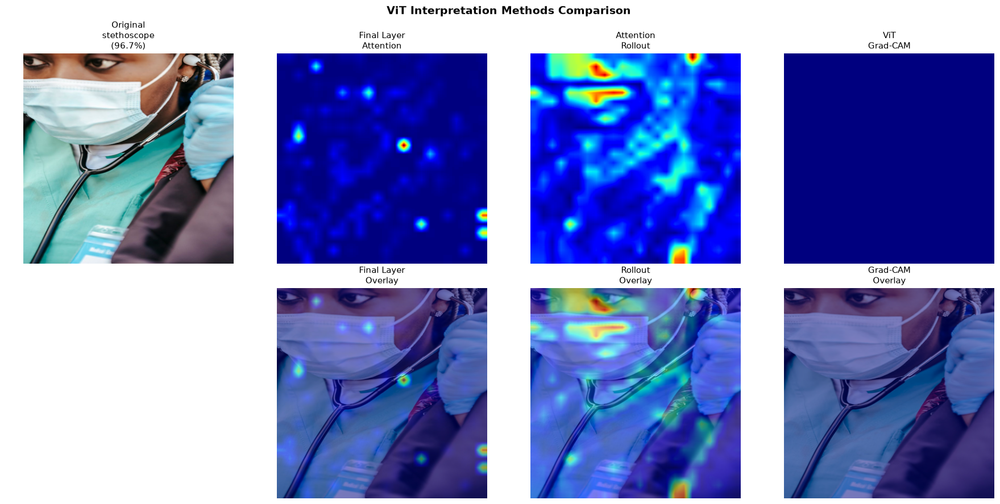


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization


In [13]:
def comprehensive_vit_interpretation(img, img_tensor, attentions, gradcam):
    """Compare all ViT interpretation methods."""
    # Get prediction
    with torch.no_grad():
        output = model(img_tensor)
        pred_class = output.argmax(dim=1).item()
        prob = F.softmax(output, dim=1)[0, pred_class].item()
    
    img_resized = img.resize((INPUT_SIZE, INPUT_SIZE))
    img_array = np.array(img_resized) / 255.0
    
    # Get final layer attention - compute grid size dynamically
    num_patches = attentions[-1].shape[-1] - 1  # Exclude CLS token
    grid_size = int(np.sqrt(num_patches))
    
    final_attn = attentions[-1][0].mean(dim=0)[0, 1:].numpy()  # Mean over heads, CLS to patches
    final_attn = final_attn.reshape(grid_size, grid_size)
    final_attn = (final_attn - final_attn.min()) / (final_attn.max() - final_attn.min())
    final_attn_resized = np.array(Image.fromarray((final_attn * 255).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
    
    # Get attention rollout
    rollout = attention_rollout(attentions)
    rollout_attn = rollout[0, 1:].numpy()
    rollout_attn = rollout_attn.reshape(grid_size, grid_size)
    rollout_attn = (rollout_attn - rollout_attn.min()) / (rollout_attn.max() - rollout_attn.min())
    rollout_attn_resized = np.array(Image.fromarray((rollout_attn * 255).astype(np.uint8)).resize((INPUT_SIZE, INPUT_SIZE), Image.BILINEAR)) / 255
    
    # Get Grad-CAM
    gradcam_heatmap, _ = gradcam(img_tensor, pred_class)
    
    # Create comparison figure
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    
    # Row 1: Heatmaps
    axes[0, 0].imshow(img_resized)
    axes[0, 0].set_title(f'Original\n{imagenet_labels[pred_class]}\n({prob*100:.1f}%)', fontsize=11)
    axes[0, 0].axis('off')
    
    axes[0, 1].imshow(final_attn_resized, cmap='jet')
    axes[0, 1].set_title('Final Layer\nAttention', fontsize=11)
    axes[0, 1].axis('off')
    
    axes[0, 2].imshow(rollout_attn_resized, cmap='jet')
    axes[0, 2].set_title('Attention\nRollout', fontsize=11)
    axes[0, 2].axis('off')
    
    axes[0, 3].imshow(gradcam_heatmap, cmap='jet')
    axes[0, 3].set_title('ViT\nGrad-CAM', fontsize=11)
    axes[0, 3].axis('off')
    
    # Row 2: Overlays
    axes[1, 0].axis('off')
    
    overlay1 = 0.5 * plt.cm.jet(final_attn_resized)[:, :, :3] + 0.5 * img_array
    axes[1, 1].imshow(np.clip(overlay1, 0, 1))
    axes[1, 1].set_title('Final Layer\nOverlay', fontsize=11)
    axes[1, 1].axis('off')
    
    overlay2 = 0.5 * plt.cm.jet(rollout_attn_resized)[:, :, :3] + 0.5 * img_array
    axes[1, 2].imshow(np.clip(overlay2, 0, 1))
    axes[1, 2].set_title('Rollout\nOverlay', fontsize=11)
    axes[1, 2].axis('off')
    
    overlay3 = 0.5 * plt.cm.jet(gradcam_heatmap)[:, :, :3] + 0.5 * img_array
    axes[1, 3].imshow(np.clip(overlay3, 0, 1))
    axes[1, 3].set_title('Grad-CAM\nOverlay', fontsize=11)
    axes[1, 3].axis('off')
    
    plt.suptitle('ViT Interpretation Methods Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
    
    print("\n" + "="*65)
    print("Summary of ViT Interpretation Methods:")
    print("="*65)
    print("\n1. Final Layer Attention:")
    print("   - Direct attention from [CLS] to patches")
    print("   - Shows what the last layer focuses on")
    print("\n2. Attention Rollout:")
    print("   - Aggregates attention across ALL layers")
    print("   - More comprehensive view of information flow")
    print("\n3. Grad-CAM:")
    print("   - Gradient-based (like CNNs)")
    print("   - Class-discriminative localization")

comprehensive_vit_interpretation(original_img, img_tensor, attentions, vit_gradcam)

## 11. Analyze All Five Objects


Analyzing all five clinical objects with the Vision Transformer...
Watch how the attention pattern changes from one object to the next.


Analyzing: STETHOSCOPE

Top 3 Predictions:
  1. stethoscope: 96.7%
  2. lab coat: 0.5%
  3. syringe: 0.5%


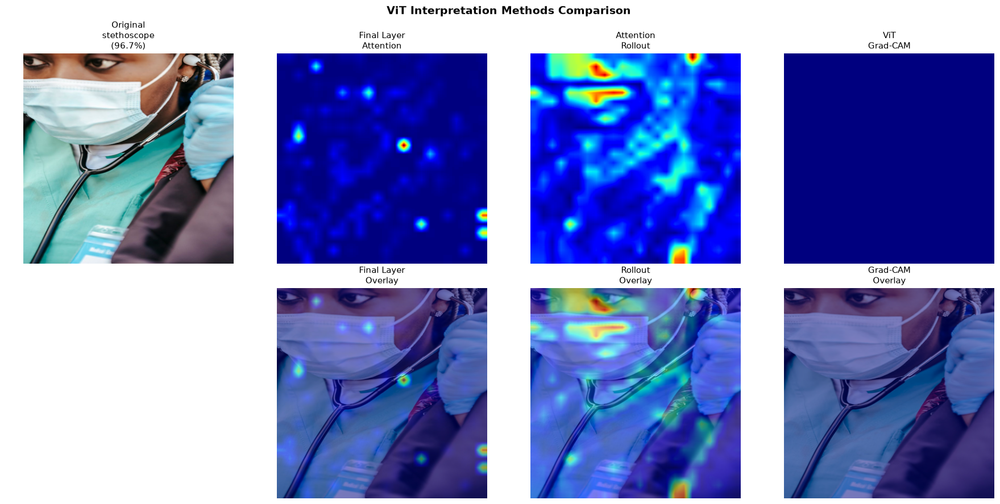


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization

Analyzing: SYRINGE

Top 3 Predictions:
  1. syringe: 99.6%
  2. lab coat: 0.1%
  3. beaker: 0.1%


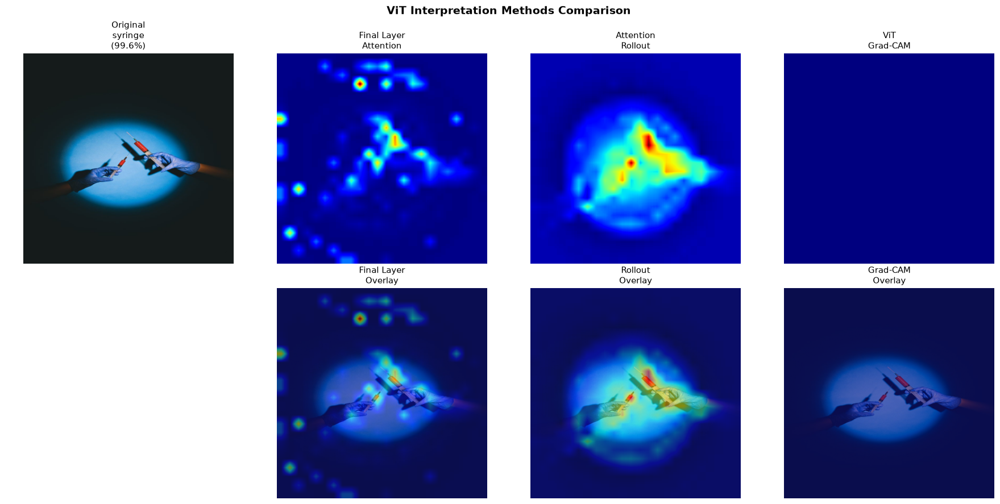


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization

Analyzing: PILL BOTTLE

Top 3 Predictions:
  1. pill bottle: 99.5%
  2. face powder: 0.0%
  3. pencil sharpener: 0.0%


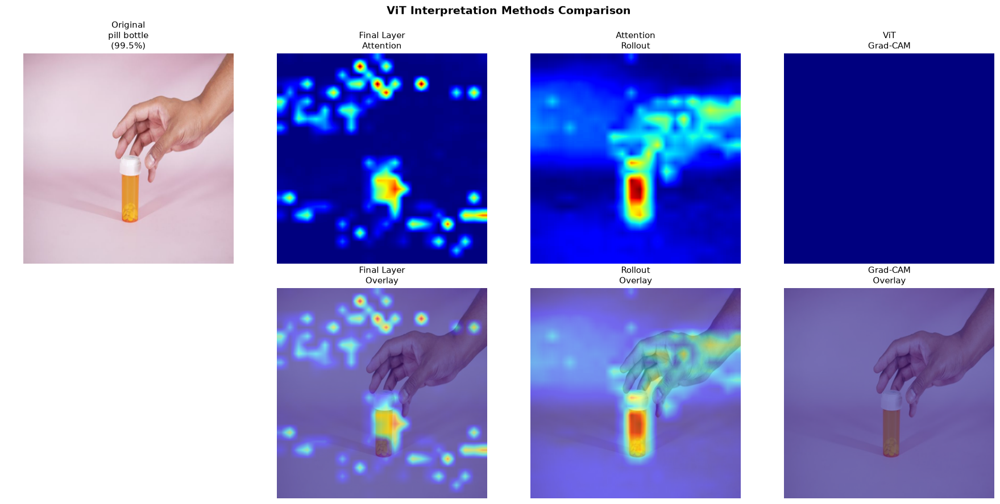


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization

Analyzing: AMBULANCE

Top 3 Predictions:
  1. ambulance: 99.7%
  2. stretcher: 0.0%
  3. police van: 0.0%


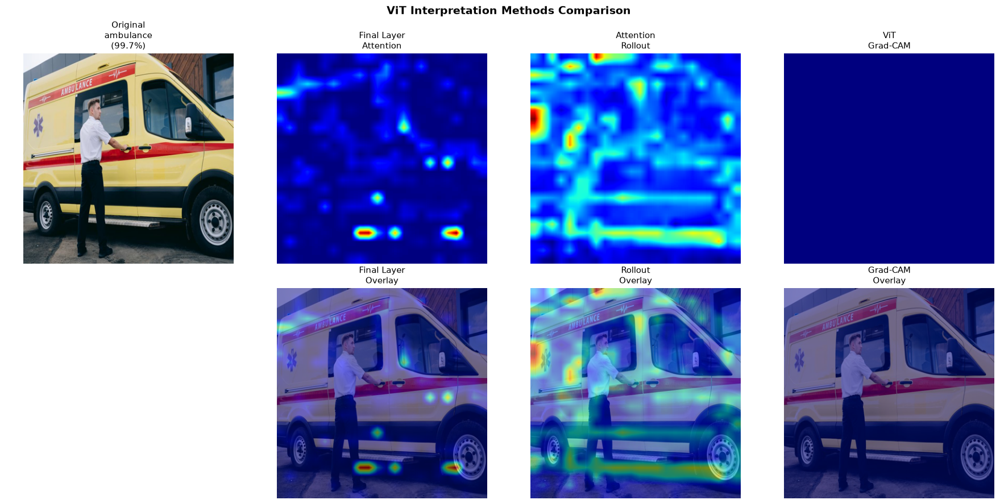


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization

Analyzing: CRUTCHES

Top 3 Predictions:
  1. crutch: 98.5%
  2. neck brace: 0.5%
  3. knee pad: 0.2%


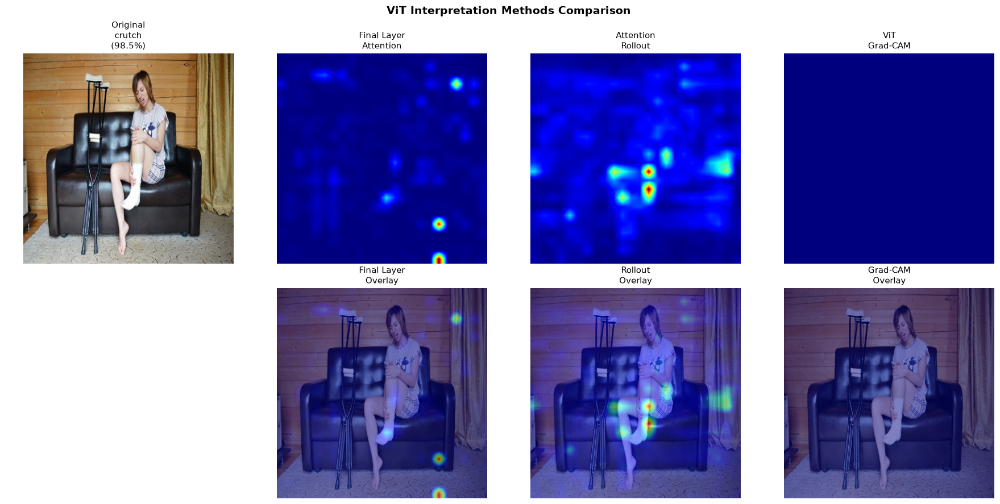


Summary of ViT Interpretation Methods:

1. Final Layer Attention:
   - Direct attention from [CLS] to patches
   - Shows what the last layer focuses on

2. Attention Rollout:
   - Aggregates attention across ALL layers
   - More comprehensive view of information flow

3. Grad-CAM:
   - Gradient-based (like CNNs)
   - Class-discriminative localization


In [14]:
def analyze_clinical_image_vit(image_key):
    """Analyze one clinical object image with the ViT interpretation methods."""
    print(f"\n{'='*60}")
    print(f"Analyzing: {image_key.replace('_', ' ').upper()}")
    print('='*60)

    # Load and preprocess
    img = load_image(sample_images[image_key])
    tensor = preprocess_image(img)

    # Get predictions
    preds = get_predictions(model, tensor, top_k=3)
    print("\nTop 3 Predictions:")
    for i, p in enumerate(preds):
        print(f"  {i+1}. {p['class']}: {p['probability']*100:.1f}%")

    # Get attention
    with torch.no_grad():
        image_attentions = attn_extractor.get_attention_weights(tensor)

    # Visualize
    comprehensive_vit_interpretation(img, tensor, image_attentions, vit_gradcam)

# Analyze every object in the sample set
print("Analyzing all five clinical objects with the Vision Transformer...")
print("Watch how the attention pattern changes from one object to the next.\n")

for key in sample_images.keys():
    analyze_clinical_image_vit(key)


## 12. Key Takeaways: CNN vs Vision Transformer

### Interpretation Differences

| Method | CNN | Vision Transformer |
|--------|-----|--------------------|
| **Primary tool** | Grad-CAM | Attention maps |
| **Built-in interpretability** | Requires hooks | Attention is inherent |
| **Spatial resolution** | Depends on layer | Fixed by patch size (16x16 here) |
| **Global context** | Limited (local receptive fields) | Full (self-attention) |

### What the attention maps actually showed

Run over the five images above, a few patterns are consistent:

- **Heads specialize, but not tidily.** Within a single layer some heads concentrate on the object itself while others spread across the background, the surface it sits on, or the person holding it. A handful behave almost positionally, attending to a fixed region regardless of content. Do not expect to find one head per semantic part — that story is appealing and mostly not true.
- **Depth sharpens focus.** Early layers attend broadly and fairly uniformly; by the last few blocks the [CLS] attention has collapsed onto a small number of patches. The interesting ones are the middle layers, where the object is already separated from the background but context has not yet been discarded.
- **Context is used, for better and worse — and this is the one to look at.** The crutches image is the instructive case. The model answers `crutch` at 98.5% confidence, but the attention rollout does not sit on the crutches at all: the heat concentrates on the woman's bandaged leg and the surrounding scene. The transformer appears to be classifying the *situation* — someone with an injured leg on a sofa — as much as the object. It happens to be right, and it is right for a reason nobody asked for. Nothing in the 98.5% tells you that; only the attention map does.

  This is the whole argument for interpretability in one picture. Change the scene and keep the crutches, and a model that learned the scene will fail in a way the test-set accuracy never predicted. It is the same failure mode as a chest-radiograph model that learned to recognize the chest drain rather than the pneumothorax (see Section 12's closing note).

- **Rollout is the more honest summary, but it is still a summary.** Single-layer attention is easy to over-read — those sparse bright dots in the final layer are as much artefacts of a few high-norm tokens as they are evidence. Attention rollout, which composes attention across every layer, is the closest thing here to "where the information came from". It is still not a causal explanation: it tells you what the model *attended to*, not what it *used*.

### When to Use Each

**CNNs are better when:**
- You need precise localization
- You are working with limited data
- Computational resources are constrained

**ViTs are better when:**
- Global context matters — a small device in a cluttered scene, or a finding whose interpretation depends on the rest of the image
- You have large datasets, or a strong pre-trained checkpoint to fine-tune
- You want interpretability that falls out of the architecture rather than being bolted on

### Healthcare AI considerations
- Attention shows whether the model looked at the object or at the surroundings — the single most useful audit question
- Attention rollout reveals the full decision pathway rather than one layer's slice of it
- Multi-head attention lets several features be tracked at once
- Patch-based processing maps naturally onto how high-resolution medical images are actually handled in production: tiled, processed per tile, then aggregated

### What changes for real medical imaging

The same four things as in the CNN notebook, whose Section 14 covers them in full: a **domain-specific model** rather than ImageNet weights; **DICOM** rather than JPEG, with windowing, 12–16 bit depth and header de-identification; **far higher resolution**, handled by tiling rather than a 384x384 resize; and the fact that saliency evidence becomes a **clinical safety requirement** rather than a teaching aid, because it is what reveals a model keying on a laterality marker, a chest drain or a scanner artefact instead of the pathology.

Public datasets to work with — NIH ChestX-ray14, CheXpert, MIMIC-CXR, the ISIC dermoscopy archive — are listed with their access conditions in Section 14 of `s3_01_cnn_image_interpretation.ipynb`. Most require a data use agreement.


In [15]:
# Cleanup
attn_extractor.remove_hooks()

print("="*60)
print("Notebook complete!")
print("="*60)
print("""
Key insights from Vision Transformer interpretation:

1. Attention heads specialize, but untidily - within one layer, some heads
   sit on the object while others spread over the background or the person
   holding it, and a few are close to purely positional
2. Later layers attend far more narrowly than early layers
3. Attention rollout, composed across all layers, is the most honest summary
4. ViT gives interpretability that falls out of the architecture itself,
   rather than needing gradients and hooks bolted on afterwards

Compare with the CNN notebook (s3_01_cnn_image_interpretation.ipynb), which runs
these same five images through ResNet50, to see how the two architectures
arrive at the same labels by visibly different routes.
""")


Notebook complete!

Key insights from Vision Transformer interpretation:

1. Attention heads specialize, but untidily - within one layer, some heads
   sit on the object while others spread over the background or the person
   holding it, and a few are close to purely positional
2. Later layers attend far more narrowly than early layers
3. Attention rollout, composed across all layers, is the most honest summary
4. ViT gives interpretability that falls out of the architecture itself,
   rather than needing gradients and hooks bolted on afterwards

Compare with the CNN notebook (s3_01_cnn_image_interpretation.ipynb), which runs
these same five images through ResNet50, to see how the two architectures
arrive at the same labels by visibly different routes.

